In [ ]:
import os

print(os.listdir())
print(uploaded.keys())

['.config', 'pima-indians-diabetes.csv', 'sample_data']
dict_keys(['pima-indians-diabetes.csv'])


In [ ]:
for root, dirs, files_list in os.walk("diabetes_data"):
    print("Folder:", root)
    print("Files:", files_list)

In [ ]:
import glob
import pandas as pd

csv_files = glob.glob("/content/**/*.csv", recursive=True)

print(csv_files)

['/content/pima-indians-diabetes.csv', '/content/sample_data/california_housing_train.csv', '/content/sample_data/mnist_test.csv', '/content/sample_data/mnist_train_small.csv', '/content/sample_data/california_housing_test.csv']


In [ ]:
df = pd.read_csv(csv_files[0])
print(df.head())
print(df.shape)

   6  148  72  35    0  33.6  0.627  50  1
0  1   85  66  29    0  26.6  0.351  31  0
1  8  183  64   0    0  23.3  0.672  32  1
2  1   89  66  23   94  28.1  0.167  21  0
3  0  137  40  35  168  43.1  2.288  33  1
4  5  116  74   0    0  25.6  0.201  30  0
(767, 9)


In [ ]:
print(df.shape)
print(df.columns)
print(df.isnull().sum())
print(df.head())

(767, 9)
Index(['6', '148', '72', '35', '0', '33.6', '0.627', '50', '1'], dtype='object')
6        0
148      0
72       0
35       0
0        0
33.6     0
0.627    0
50       0
1        0
dtype: int64
   6  148  72  35    0  33.6  0.627  50  1
0  1   85  66  29    0  26.6  0.351  31  0
1  8  183  64   0    0  23.3  0.672  32  1
2  1   89  66  23   94  28.1  0.167  21  0
3  0  137  40  35  168  43.1  2.288  33  1
4  5  116  74   0    0  25.6  0.201  30  0


In [ ]:
df = pd.read_csv(csv_files[0], header=None)

df.columns = [
    "Pregnancies", "Glucose", "BloodPressure",
    "SkinThickness", "Insulin", "BMI",
    "DiabetesPedigreeFunction", "Age", "Outcome"
]

print(df.head())
print(df.shape)
print(df.columns)


   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
(768, 9)
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import numpy as np

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

cols = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
X[cols] = X[cols].replace(0, np.nan)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LinearRegression()
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_pred_class = (y_pred >= 0.5).astype(int)

print("Model Training Completed!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Model Training Completed!
Training records: 614
Testing records: 154


In [ ]:
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_class)

print("Confusion Matrix:\n", cm)
print("TP:", cm[1,1])
print("TN:", cm[0,0])
print("FP:", cm[0,1])
print("FN:", cm[1,0])

print("Accuracy:", accuracy_score(y_test, y_pred_class)*100)
print("Precision:", precision_score(y_test, y_pred_class)*100)
print("Recall:", recall_score(y_test, y_pred_class)*100)
print("F1 Score:", f1_score(y_test, y_pred_class)*100)

Confusion Matrix:
 [[82 18]
 [28 26]]
TP: 26
TN: 82
FP: 18
FN: 28
Accuracy: 70.12987012987013
Precision: 59.09090909090909
Recall: 48.148148148148145
F1 Score: 53.06122448979592


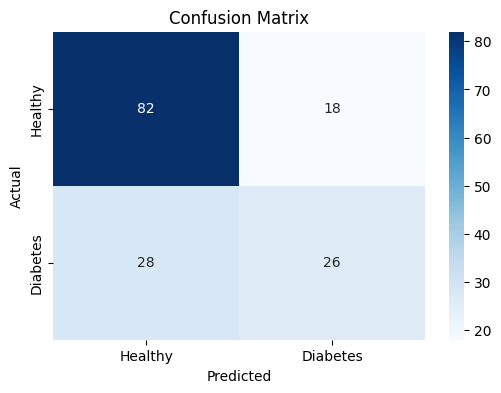

In [ ]:
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Healthy","Diabetes"],
            yticklabels=["Healthy","Diabetes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

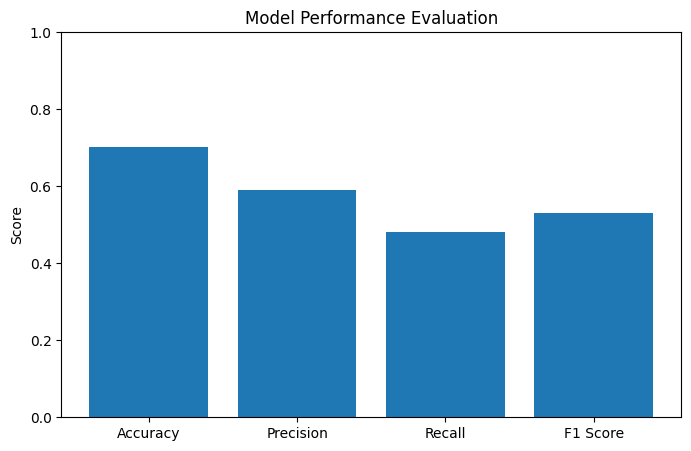

In [ ]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_class),
    "Precision": precision_score(y_test, y_pred_class),
    "Recall": recall_score(y_test, y_pred_class),
    "F1 Score": f1_score(y_test, y_pred_class)
}

plt.figure(figsize=(8,5))
plt.bar(metrics.keys(), metrics.values())
plt.ylim(0,1)
plt.ylabel("Score")
plt.title("Model Performance Evaluation")
plt.show()

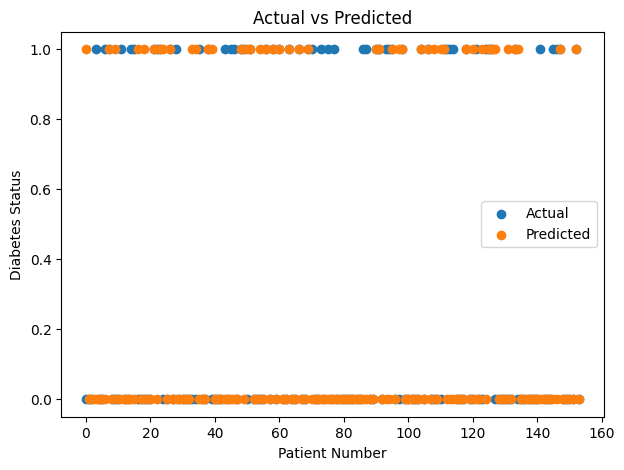

In [ ]:
plt.figure(figsize=(7,5))
plt.scatter(range(len(y_test)), y_test, label="Actual")
plt.scatter(range(len(y_pred_class)), y_pred_class, label="Predicted")
plt.xlabel("Patient Number")
plt.ylabel("Diabetes Status")
plt.title("Actual vs Predicted")
plt.legend()
plt.show()

**RESULT:**

The Pima Indians Diabetes dataset was successfully downloaded from Kaggle and implemented in Google Colab using the Least Squares Method (Linear Regression).

The model was evaluated using a confusion matrix and performance metrics.

The obtained results are:

- Accuracy: 70.13%
- Precision: 59.09%
- Recall: 48.15%
- F1-Score: 53.06%

Three visualizations were generated: Confusion Matrix, Model Performance Evaluation and Actual vs Predicted Values.

**CONCLUSION:**

Thus, the Least Squares Method was implemented successfully for diabetes prediction. The model achieved an accuracy of 70.13%, and its performance was evaluated using classification metrics and graphical visualizations.